Original Dataset:
[[ 2  3]
 [ 3  4]
 [ 4  2]
 [10 12]
 [11 13]
 [12 11]
 [20 22]
 [21 23]
 [22 21]]

Cluster Assignments:
[2 3] belongs to Cluster 0
[3 4] belongs to Cluster 0
[4 2] belongs to Cluster 0
[10 12] belongs to Cluster 1
[11 13] belongs to Cluster 1
[12 11] belongs to Cluster 1
[20 22] belongs to Cluster 2
[21 23] belongs to Cluster 2
[22 21] belongs to Cluster 2

Final Medoids:
[[ 2  3]
 [10 12]
 [20 22]]

Total Clustering Cost: 10.950844619618653


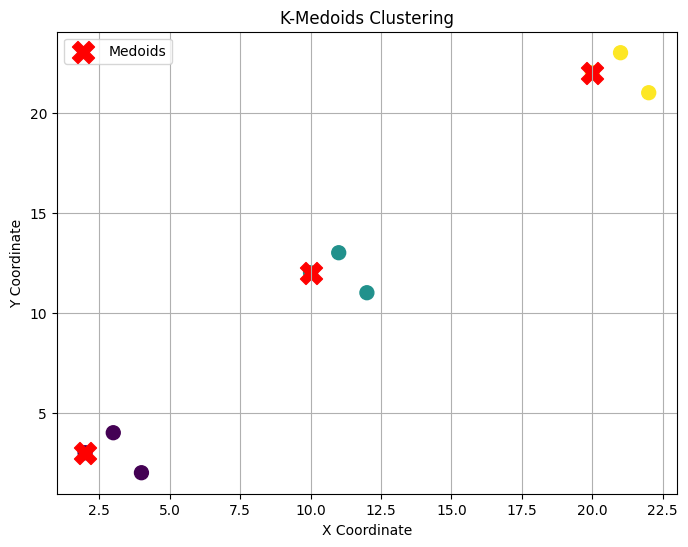


K-Medoids Clustering Completed Successfully!


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Dataset
data = np.array([[2, 3], [3, 4], [4, 2],
                 [10, 12], [11, 13], [12, 11],
                 [20, 22], [21, 23], [22, 21]])
print("Original Dataset:")
print(data)

# Step 2: Distance between every pair of points
distance = np.linalg.norm(data[:, None] - data[None, :], axis=2)

# Step 3: Initial medoids (indices of 3 data points)
medoids = [0, 3, 6]

# Step 4: Cost = sum of distance of each point to its nearest medoid
def cost(m):
    return distance[:, m].min(axis=1).sum()

# Step 5: Keep swapping a medoid with a non-medoid while the cost reduces
improved = True
while improved:
    improved = False
    for i in range(len(medoids)):
        for c in range(len(data)):
            if c not in medoids:
                trial = medoids.copy()
                trial[i] = c
                if cost(trial) < cost(medoids):
                    medoids = trial
                    improved = True

# Step 6: Assign each point to its nearest medoid
labels = distance[:, medoids].argmin(axis=1)

# Step 7: Results
print("\nCluster Assignments:")
for point, label in zip(data, labels):
    print(point, "belongs to Cluster", label)

print("\nFinal Medoids:")
print(data[medoids])
print("\nTotal Clustering Cost:", cost(medoids))

# Step 8: Plot
plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], c=labels, cmap='viridis', s=100)
plt.scatter(data[medoids, 0], data[medoids, 1], color='red',
            marker='X', s=250, label='Medoids')
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("K-Medoids Clustering")
plt.legend()
plt.grid(True)
plt.show()

print("\nK-Medoids Clustering Completed Successfully!")
